# Clasificador de noticias AG News con TF-IDF
Pre-entrega Módulo 3 · Luque Vicleniz

## 1. Instalación y carga de datos

In [29]:
!pip install -q spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 10.4 MB/s  0:00:01
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [30]:

import sys

try:
    # Si estamos en Colab, usamos la carpeta del Drive
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA = "/content/drive/MyDrive/NLP_Modulo2"
except ImportError:
    # Fuera de Colab (repo clonado): usamos la carpeta actual
    RUTA = "."

sys.path.insert(0, RUTA)
from cargar_dataset import cargar

train_df, test_df = cargar()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [31]:
print("Train:", train_df.shape)
print("Test:", test_df.shape)
print(train_df["label"].value_counts())

Train: (8000, 2)
Test: (2000, 2)
label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64


## 2. Preprocesamiento (reutilizado del Módulo 2)

In [32]:
import re, html

AGENCIAS = r"(?:AP|Reuters|AFP|UPI|AP Photo|Canadian Press|Reuters Photo)"

def limpiar_html(texto):
    # '#39;' -> "'" (el número es el código del carácter)
    texto = re.sub(r"(?<![&\w])#(\d+);", lambda m: chr(int(m.group(1))), texto)
    # 'quot;', 'amp;'... sin '&' inicial -> les devolvemos el '&'
    texto = re.sub(r"(?<![&\w])(quot|amp|lt|gt|nbsp);", r"&\1;", texto)
    # decodificamos entidades (&lt; -> <) y borramos los tags <...>
    texto = html.unescape(html.unescape(texto))
    return re.sub(r"<[^>]+>", " ", texto)

def limpiar_ruido_web(texto):
    texto = re.sub(r"\([^()]*Quote,\s*Profile,\s*Research\s*\)", " ", texto)   # boilerplate bursátil
    texto = re.sub(r"https?://\S+|www\.\S+", " ", texto)                       # URLs
    texto = re.sub(r"\b[\w-]+(?:\.[\w-]+)*\.(?:com|org|net|edu|gov|co\.uk)\b", " ", texto, flags=re.I)  # dominios
    texto = re.sub(rf"\(\s*{AGENCIAS}\s*\)", " ", texto)                       # (AP), (Reuters)
    texto = re.sub(rf"\b{AGENCIAS}\s+-\s+", " ", texto)                        # 'AP - '
    return texto.lower()                                                       # minúsculas al final

def normalizar(texto):
    texto = re.sub(r"\bcan['’]t\b", "cannot", texto)
    texto = re.sub(r"\bwon['’]t\b", "will not", texto)
    texto = re.sub(r"\bu\.s\.a?\.?", "us", texto)
    texto = re.sub(r"n['’]t\b", " not", texto)               # las negaciones se conservan
    texto = re.sub(r"['’](s|re|ve|ll|d|m)\b", " ", texto)    # posesivos y contracciones
    texto = re.sub(r"[^a-z\s]", " ", texto)                  # dígitos, puntuación, símbolos
    return re.sub(r"\s+", " ", texto).strip()

def clean_text(texto):
    return normalizar(limpiar_ruido_web(limpiar_html(str(texto))))

In [33]:
import spacy
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])   # sin parser ni NER: más rápido

def _lemas(doc):
    # lema en minúsculas; descartamos espacios y tokens de una sola letra
    return [t.lemma_.lower() for t in doc if not t.is_space and len(t.text) > 1]

def procesar(df):
    textos = [clean_text(x) for x in df["text"]]
    df["tokens"] = [_lemas(d) for d in nlp.pipe(textos, batch_size=500)]
    df["clean"] = df["tokens"].apply(" ".join)    # texto limpio y lematizado
    df["n_tokens"] = df["tokens"].apply(len)
    return df

train_df = procesar(train_df)
test_df = procesar(test_df)

In [34]:
print(train_df[["text", "clean"]].head(3))
print("Vacíos en train:", (train_df["n_tokens"] == 0).sum())
print("Vacíos en test:", (test_df["n_tokens"] == 0).sum())

                                                text  \
0  Red Hat Appoints New CFO. September 2, 2004 --...   
1  Sprint, SBC In Hotspot Roaming Deal. Sprint an...   
2  Radio Outage Grounds West Coast Flights. Airpo...   

                                               clean  
0  red hat appoint new cfo september web host ind...  
1  sprint sbc in hotspot roam deal sprint and sbc...  
2  radio outage ground west coast flights airport...  
Vacíos en train: 0
Vacíos en test: 0


## 3. Vectorización TF-IDF y baseline con Regresión Logística

In [35]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer = TfidfVectorizer()    # parámetros por defecto: es el punto de partida

X_train = vectorizer.fit_transform(train_df["clean"])   # aprende el vocabulario y el IDF, y transforma
X_test = vectorizer.transform(test_df["clean"])         # solo transforma, usando lo aprendido en train

y_train = train_df["label"]
y_test = test_df["label"]

In [36]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Palabras en el vocabulario:", len(vectorizer.vocabulary_))

X_train: (8000, 17025)
X_test: (2000, 17025)
Palabras en el vocabulario: 17025


In [37]:
from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(max_iter=1000)   # max_iter: tope de iteraciones del optimizador
modelo.fit(X_train, y_train)                 # aprende SOLO con train
y_pred = modelo.predict(X_test)              # predice las 2.000 noticias del test

In [38]:
from sklearn.metrics import accuracy_score, f1_score

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1-macro:", f1_score(y_test, y_pred, average="macro"))

Accuracy: 0.8835
F1-macro: 0.883164675015612


## 4. Evaluación del baseline: reporte y matriz de confusión

In [40]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

    Business      0.842     0.842     0.842       500
    Sci_Tech      0.862     0.864     0.863       500
      Sports      0.927     0.966     0.946       500
       World      0.902     0.862     0.881       500

    accuracy                          0.883      2000
   macro avg      0.883     0.883     0.883      2000
weighted avg      0.883     0.883     0.883      2000



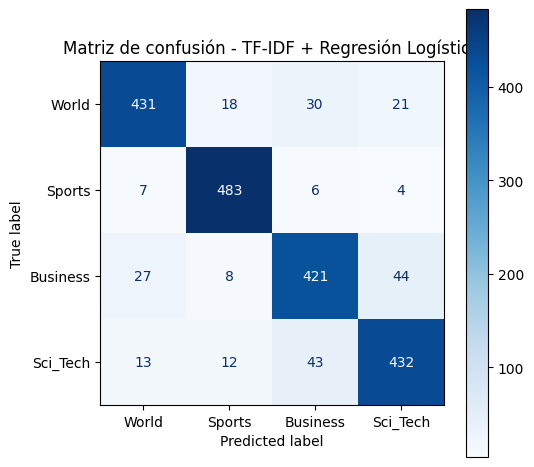

In [41]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

orden = ["World", "Sports", "Business", "Sci_Tech"]

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=orden, cmap="Blues", ax=ax)
ax.set_title("Matriz de confusión - TF-IDF + Regresión Logística")
plt.tight_layout()
plt.savefig(RUTA + "/matriz_confusion.png", dpi=170)   # se guarda en el Drive para el README
plt.show()

## 5. Experimentos: max_features y ngram_range (validación cruzada sobre train)

In [42]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

resultados = []
for max_feat in [2000, 5000, 10000, None]:       # None = sin límite de vocabulario
    for ngr in [(1, 1), (1, 2)]:
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=max_feat, ngram_range=ngr)),
            ("clf", LogisticRegression(max_iter=1000)),
        ])
        # validación cruzada SOLO sobre train: el test no interviene
        puntajes = cross_val_score(pipe, train_df["clean"], y_train, cv=3, scoring="f1_macro")
        resultados.append({"max_features": max_feat, "ngram_range": ngr, "f1_macro_cv": round(puntajes.mean(), 4)})

tabla = pd.DataFrame(resultados).sort_values("f1_macro_cv", ascending=False)
print(tabla.to_string(index=False))

 max_features ngram_range  f1_macro_cv
      10000.0      (1, 1)       0.8765
          NaN      (1, 1)       0.8760
       5000.0      (1, 1)       0.8744
      10000.0      (1, 2)       0.8737
       5000.0      (1, 2)       0.8709
          NaN      (1, 2)       0.8704
       2000.0      (1, 1)       0.8661
       2000.0      (1, 2)       0.8567


In [43]:
tabla.to_csv(RUTA + "/experimentos_tfidf.csv", index=False)

In [44]:
final = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 1))),
    ("clf", LogisticRegression(max_iter=1000)),
])

final.fit(train_df["clean"], y_train)           # el Pipeline hace fit_transform solo con train
y_pred_final = final.predict(test_df["clean"])  # y transform (sin refit) sobre el test

In [45]:
print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("F1-macro:", f1_score(y_test, y_pred_final, average="macro"))

Accuracy: 0.883
F1-macro: 0.8826923329776045


## 6. Comparación de clasificadores (validación cruzada sobre train)

In [46]:
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

modelos = {
    "Regresión Logística": LogisticRegression(max_iter=1000),
    "SVM lineal": LinearSVC(),
    "Naive Bayes": MultinomialNB(),
}

filas = []
for nombre, clf in modelos.items():
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 1))),   # misma configuración para todos
        ("clf", clf),
    ])
    puntajes = cross_val_score(pipe, train_df["clean"], y_train, cv=3, scoring="f1_macro")
    filas.append({"modelo": nombre, "f1_macro_cv": round(puntajes.mean(), 4)})

comparacion = pd.DataFrame(filas).sort_values("f1_macro_cv", ascending=False)
print(comparacion.to_string(index=False))
comparacion.to_csv(RUTA + "/comparacion_modelos.csv", index=False)

             modelo  f1_macro_cv
        Naive Bayes       0.8849
Regresión Logística       0.8765
         SVM lineal       0.8755


## 6b. Efecto de filtrar stop-words (validación cruzada sobre train)

In [47]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Lista de scikit-learn SIN las negaciones, que cambian el sentido de una frase
NEGACIONES = {"no", "not", "nor", "never", "none", "cannot", "nothing", "neither", "nobody", "nowhere"}
STOP = list(set(ENGLISH_STOP_WORDS) - NEGACIONES)

filas = []
for nombre, clf in [("Naive Bayes", MultinomialNB()), ("Regresión Logística", LogisticRegression(max_iter=1000))]:
    for etiqueta, sw in [("sin filtrar", None), ("stop-words filtradas", STOP)]:
        pipe = Pipeline([
            ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 1), stop_words=sw)),
            ("clf", clf),
        ])
        puntajes = cross_val_score(pipe, train_df["clean"], y_train, cv=3, scoring="f1_macro")
        filas.append({"modelo": nombre, "stop_words": etiqueta, "f1_macro_cv": round(puntajes.mean(), 4)})

tabla_sw = pd.DataFrame(filas)
print(tabla_sw.to_string(index=False))
tabla_sw.to_csv(RUTA + "/experimento_stopwords.csv", index=False)

             modelo           stop_words  f1_macro_cv
        Naive Bayes          sin filtrar       0.8849
        Naive Bayes stop-words filtradas       0.8847
Regresión Logística          sin filtrar       0.8765
Regresión Logística stop-words filtradas       0.8792


In [48]:
for etiqueta, sw in [("sin filtrar", None), ("stop-words filtradas", STOP)]:
    v = TfidfVectorizer(stop_words=sw).fit(train_df["clean"])   # se ajusta solo con train
    print(etiqueta, "->", len(v.vocabulary_), "palabras")

sin filtrar -> 17025 palabras
stop-words filtradas -> 16772 palabras


## 7. Modelo final: Naive Bayes evaluado en el test

In [49]:
final_nb = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10000, ngram_range=(1, 1))),   # misma configuración que antes
    ("clf", MultinomialNB()),
])

final_nb.fit(train_df["clean"], y_train)          # aprende solo con train
y_pred_nb = final_nb.predict(test_df["clean"])    # el test solo se transforma y se predice

In [50]:
print("Accuracy:", accuracy_score(y_test, y_pred_nb))
print("F1-macro:", f1_score(y_test, y_pred_nb, average="macro"))
print()
print(classification_report(y_test, y_pred_nb, digits=3))

Accuracy: 0.8895
F1-macro: 0.8896533400114911

              precision    recall  f1-score   support

    Business      0.826     0.866     0.846       500
    Sci_Tech      0.876     0.858     0.867       500
      Sports      0.954     0.960     0.957       500
       World      0.905     0.874     0.889       500

    accuracy                          0.889      2000
   macro avg      0.890     0.890     0.890      2000
weighted avg      0.890     0.889     0.890      2000



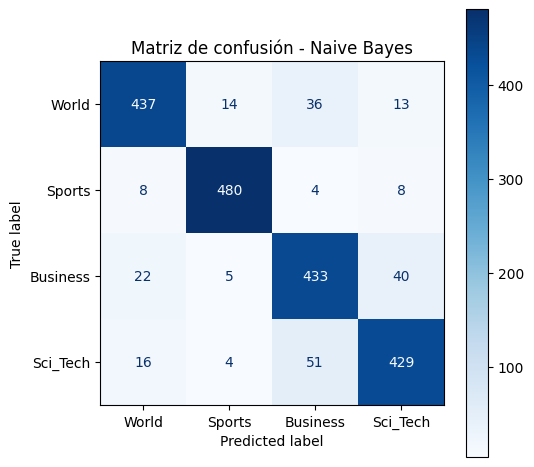

In [51]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_nb, labels=orden, cmap="Blues", ax=ax)
ax.set_title("Matriz de confusión - Naive Bayes")
plt.tight_layout()
plt.savefig(RUTA + "/matriz_confusion_nb.png", dpi=170)
plt.show()

## 8. Análisis de errores


In [52]:
# Noticias que eran Business pero el modelo predijo Sci_Tech
err1 = test_df[(y_test == "Business") & (y_pred_nb == "Sci_Tech")]
for t in err1["text"].head(4):
    print("-", t[:220])
    print()

- Symantec Said to Be in Talks for Veritas. Symantec, which produces the Norton line of computer products, is in talks to acquire Veritas Software, a maker of data backup programs.

- Dropping Hyphen, Some Great Old Stores Become Just Macy #39;s. n the not-so-distant past, the names Burdines, Rich #39;s, Goldsmith #39;s, Bon March and Lazarus had a local glory as the emporiums where customers bought t

- AOL Is Said to Plan 700 Layoffs. America Online, the country #39;s leading Internet service, is preparing to lay off as many as 700 of its 13,000 employees in the United States, according to an executive knowledgeable ab

- PC Sales Hot For 2004, But Will Soon Cool Off. PC shipments in the second quarter grew faster than any three-month period since 1999, IDC said Monday, citing the continued pent-up demand for replacement systems as the dr



In [53]:
# Noticias que eran Sci_Tech pero el modelo predijo Business
err2 = test_df[(y_test == "Sci_Tech") & (y_pred_nb == "Business")]
for t in err2["text"].head(4):
    print("-", t[:220])
    print()

- E.U. Regulators Approve Oracle's PeopleSoft Bid. European Union antitrust regulators on Tuesday cleared Oracle Corp.'s hostile $7.7 billion bid for rival business software maker PeopleSoft Inc., removing one of the last 

- Make hotels just like home. HOTEL operators, take note: Todays hotel guests are making a nonsense of room-pricing strategies with their aggressive, Internet-aided discount-hunting.

- ANOTHER VOICE Sugary drinks bad for you. Many studies have linked the consumption of nondiet soda and fruit juices with added sugars to obesity and attendant risks of diabetes.

- Supreme Court Asked To Hear File-Sharing Arguments. The file-sharing legal battle has moved to the Supreme Court, with a group composed of labor unions, sports leagues and state attorneys general asking for a hearing on 



## 9. requirements.txt

In [54]:
import sklearn, pandas, numpy, matplotlib, spacy

reqs = f"""pandas=={pandas.__version__}
numpy=={numpy.__version__}
scikit-learn=={sklearn.__version__}
matplotlib=={matplotlib.__version__}
spacy=={spacy.__version__}
"""
open(RUTA + "/requirements.txt", "w").write(reqs)
print(reqs)

pandas==2.2.3
numpy==2.4.6
scikit-learn==1.6.1
matplotlib==3.10.0
spacy==3.8.18

